In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sklearn
import xgboost
import lightgbm
import shap

In [4]:
df = pd.read_csv("../data/home_credit_dataset.csv")

In [5]:
df

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,428247,0,Cash loans,F,N,N,0,157500.0,634500.0,30523.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,140966,0,Cash loans,M,Y,Y,1,90000.0,1223010.0,51948.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,407283,0,Revolving loans,F,N,Y,0,405000.0,540000.0,27000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,434300,0,Cash loans,F,N,N,0,90000.0,439740.0,18630.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,5.0
4,446788,0,Cash loans,F,N,N,0,67500.0,323388.0,18054.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
246003,279971,0,Cash loans,F,N,N,0,90000.0,284400.0,16456.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
246004,279381,0,Cash loans,F,N,N,0,67500.0,1080000.0,31576.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
246005,397830,0,Cash loans,F,N,N,0,157500.0,509400.0,28444.5,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,2.0
246006,213394,0,Cash loans,F,N,Y,0,225000.0,83538.0,6376.5,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,1.0


In [6]:
df["TARGET"].value_counts()

TARGET
0    226257
1     19751
Name: count, dtype: int64

In [7]:
df["TARGET"].value_counts(normalize=True)*100

TARGET
0    91.971399
1     8.028601
Name: proportion, dtype: float64

In [8]:
missing = df.isnull().mean()*100

In [9]:
missing=missing.sort_values(ascending=False)

In [10]:
missing.head(20)

COMMONAREA_AVG              69.993252
COMMONAREA_MODE             69.993252
COMMONAREA_MEDI             69.993252
NONLIVINGAPARTMENTS_MEDI    69.548958
NONLIVINGAPARTMENTS_MODE    69.548958
NONLIVINGAPARTMENTS_AVG     69.548958
FONDKAPREMONT_MODE          68.518503
LIVINGAPARTMENTS_AVG        68.491269
LIVINGAPARTMENTS_MEDI       68.491269
LIVINGAPARTMENTS_MODE       68.491269
FLOORSMIN_MODE              67.987626
FLOORSMIN_AVG               67.987626
FLOORSMIN_MEDI              67.987626
YEARS_BUILD_AVG             66.656369
YEARS_BUILD_MODE            66.656369
YEARS_BUILD_MEDI            66.656369
OWN_CAR_AGE                 66.055982
LANDAREA_MEDI               59.524893
LANDAREA_AVG                59.524893
LANDAREA_MODE               59.524893
dtype: float64

In [11]:
(missing>0).sum()

np.int64(67)

In [12]:
df.groupby("NAME_INCOME_TYPE")["TARGET"].mean().sort_values(ascending=False) * 100

NAME_INCOME_TYPE
Unemployed              31.578947
Maternity leave         25.000000
Working                  9.551976
Commercial associate     7.471586
State servant            5.678487
Pensioner                5.286951
Businessman              0.000000
Student                  0.000000
Name: TARGET, dtype: float64

In [13]:
df["NAME_INCOME_TYPE"].value_counts()

NAME_INCOME_TYPE
Working                 127136
Commercial associate     57190
Pensioner                44241
State servant            17399
Unemployed                  19
Student                     11
Businessman                  8
Maternity leave              4
Name: count, dtype: int64

In [14]:
df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365
df["AGE_YEARS"].describe()

count    246008.000000
mean         43.923648
std          11.958515
min          20.517808
25%          33.994521
50%          43.128767
75%          53.912329
max          69.120548
Name: AGE_YEARS, dtype: float64

In [15]:
df["AGE_GROUP"] = pd.cut(df["AGE_YEARS"], bins=[20, 30, 40, 50, 60, 70])
df.groupby("AGE_GROUP")["TARGET"].mean() * 100

AGE_GROUP
(20, 30]    11.394120
(30, 40]     9.497971
(40, 50]     7.645225
(50, 60]     6.102924
(60, 70]     4.856178
Name: TARGET, dtype: float64

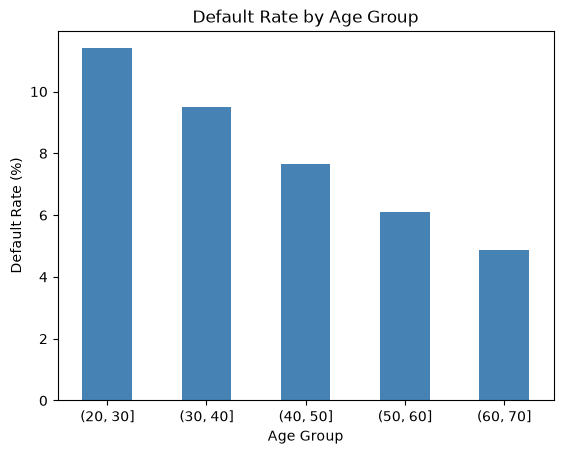

In [17]:
 

age_rate = df.groupby("AGE_GROUP")["TARGET"].mean() * 100

age_rate.plot(kind="bar", color="steelblue")
plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.show()

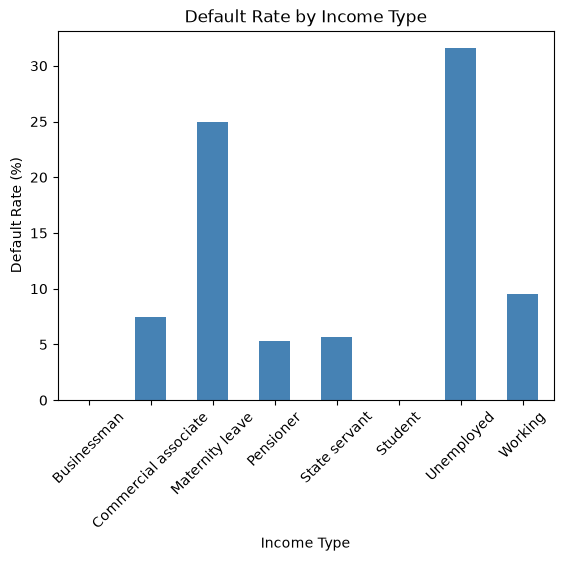

In [19]:
income_rate = df.groupby("NAME_INCOME_TYPE")["TARGET"].mean() * 100

income_rate.plot(kind="bar", color="steelblue")
plt.title("Default Rate by Income Type")
plt.xlabel("Income Type")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.show()

In [20]:
df[["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY"]].describe()

,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY
count,2.460080e+05,2.460080e+05,246000.000000
mean,1.688316e+05,5.991707e+05,27108.618494
std,2.606022e+05,4.034845e+05,14511.696128
min,2.565000e+04,4.500000e+04,1980.000000
25%,1.125000e+05,2.700000e+05,16506.000000
50%,1.440000e+05,5.124465e+05,24903.000000
75%,2.025000e+05,8.086500e+05,34600.500000
max,1.170000e+08,4.050000e+06,258025.500000


In [21]:
df["CREDIT_INCOME_RATIO"] = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]

df["RATIO_GROUP"] = pd.qcut(df["CREDIT_INCOME_RATIO"], q=5)
df.groupby("RATIO_GROUP")["TARGET"].mean() * 100

RATIO_GROUP
(0.00381, 1.818]    7.330331
(1.818, 2.764]      8.476022
(2.764, 3.907]      9.003667
(3.907, 5.79]       8.211716
(5.79, 84.737]      7.124708
Name: TARGET, dtype: float64

In [22]:
cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "AGE_YEARS", "CREDIT_INCOME_RATIO", "AMT_INCOME_TOTAL"]
df[cols + ["TARGET"]].corr()["TARGET"].sort_values()

EXT_SOURCE_3          -0.178964
EXT_SOURCE_2          -0.159541
EXT_SOURCE_1          -0.155106
AGE_YEARS             -0.078242
CREDIT_INCOME_RATIO   -0.008472
AMT_INCOME_TOTAL      -0.002292
TARGET                 1.000000
Name: TARGET, dtype: float64

In [23]:
# 3. Default rate for a few yes/no and category columns
for col in ["CODE_GENDER", "FLAG_OWN_CAR", "NAME_EDUCATION_TYPE"]:
    print(f"\nDefault rate by {col} (%):")
    print((df.groupby(col)["TARGET"].mean() * 100).round(1))


Default rate by CODE_GENDER (%):
CODE_GENDER
F       7.0
M      10.1
XNA     0.0
Name: TARGET, dtype: float64

Default rate by FLAG_OWN_CAR (%):
FLAG_OWN_CAR
N    8.4
Y    7.2
Name: TARGET, dtype: float64

Default rate by NAME_EDUCATION_TYPE (%):
NAME_EDUCATION_TYPE
Academic degree                   0.0
Higher education                  5.3
Incomplete higher                 8.1
Lower secondary                  10.6
Secondary / secondary special     8.9
Name: TARGET, dtype: float64


In [26]:
df["DAYS_EMPLOYED"].describe()/365

count     673.994521
mean      174.630532
std       386.891792
min       -49.073973
25%        -7.569863
50%        -3.328767
75%        -0.794521
max      1000.665753
Name: DAYS_EMPLOYED, dtype: float64

In [25]:
(df["DAYS_EMPLOYED"] > 0).sum()

np.int64(44250)

In [28]:

df["DAYS_EMPLOYED_ANOMALY"] = (df["DAYS_EMPLOYED"] == 365243).astype(int)
df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)

print(df["DAYS_EMPLOYED_ANOMALY"].sum())
print((df["DAYS_EMPLOYED"] / -365).describe())

44250
count    201758.000000
mean          6.537295
std           6.404901
min          -0.000000
25%           2.101370
50%           4.512329
75%           8.712329
max          49.073973
Name: DAYS_EMPLOYED, dtype: float64


In [29]:
drop_cols = ["SK_ID_CURR", "CODE_GENDER", "AGE_GROUP", "RATIO_GROUP"]
df = df.drop(columns=drop_cols)

print(df.shape)

(246008, 123)


In [31]:
cat_cols = df.select_dtypes(include="object").columns

# Columns with only 2 values → label encoding (0/1)
two_value_cols = [c for c in cat_cols if df[c].nunique() == 2]
for c in two_value_cols:
    df[c] = df[c].astype("category").cat.codes

# Columns with more values → one-hot encoding
many_value_cols = [c for c in cat_cols if c not in two_value_cols]
df = pd.get_dummies(df, columns=many_value_cols, dtype=int)

print("Label-encoded:", two_value_cols)
print("One-hot encoded:", len(many_value_cols), "columns")
print("New shape:", df.shape)
print("Text columns left:", len(df.select_dtypes(include="object").columns))

C:\Users\dasra\AppData\Local\Temp\ipykernel_23588\1536756032.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns


Label-encoded: ['NAME_CONTRACT_TYPE', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'EMERGENCYSTATE_MODE']
One-hot encoded: 11 columns
New shape: (246008, 241)
Text columns left: 0


In [32]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["TARGET"])
y = df["TARGET"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Default % in train:", round(y_train.mean() * 100, 2))
print("Default % in test: ", round(y_test.mean() * 100, 2))

Train: (196806, 240)  Test: (49202, 240)
Default % in train: 8.03
Default % in test:  8.03


In [33]:
train_medians = X_train.median()

X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print("Blanks left in train:", X_train.isnull().sum().sum())
print("Blanks left in test: ", X_test.isnull().sum().sum())

Blanks left in train: 0
Blanks left in test:  0


In [34]:
X_train.to_csv("../data/X_train.csv", index=False)
X_test.to_csv("../data/X_test.csv", index=False)
y_train.to_csv("../data/y_train.csv", index=False)
y_test.to_csv("../data/y_test.csv", index=False)

In [36]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

lr = LogisticRegression(class_weight="balanced", max_iter=1000)
lr.fit(X_train_s, y_train)

test_prob = lr.predict_proba(X_test_s)[:, 1]
print("Baseline ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))

Baseline ROC-AUC: 0.7445


In [38]:
import re

clean_names = [re.sub(r"[^A-Za-z0-9_]", "_", c) for c in X_train.columns]
X_train.columns = clean_names
X_test.columns = clean_names

print(X_train.columns[:10].tolist())

['NAME_CONTRACT_TYPE', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH']


In [39]:
import lightgbm as lgb

lgbm = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    class_weight="balanced",
    random_state=42,
    verbose=-1
)
lgbm.fit(X_train, y_train)

test_prob_lgbm = lgbm.predict_proba(X_test)[:, 1]
print("LightGBM ROC-AUC:", round(roc_auc_score(y_test, test_prob_lgbm), 4))

LightGBM ROC-AUC: 0.7527


In [41]:
def add_features(d):
    d = d.copy()
    d["ANNUITY_INCOME_RATIO"] = d["AMT_ANNUITY"] / d["AMT_INCOME_TOTAL"]
    d["CREDIT_TERM"] = d["AMT_ANNUITY"] / d["AMT_CREDIT"]
    d["GOODS_CREDIT_RATIO"] = d["AMT_GOODS_PRICE"] / d["AMT_CREDIT"]
    d["EMPLOYED_AGE_RATIO"] = d["DAYS_EMPLOYED"] / d["DAYS_BIRTH"]
    d["INCOME_PER_PERSON"] = d["AMT_INCOME_TOTAL"] / d["CNT_FAM_MEMBERS"]
    ext = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
    d["EXT_MEAN"] = d[ext].mean(axis=1)
    d["EXT_MIN"] = d[ext].min(axis=1)
    return d

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)

lgbm_fe = lgb.LGBMClassifier(
    n_estimators=500, learning_rate=0.05, num_leaves=31,
    class_weight="balanced", random_state=42, verbose=-1
)
lgbm_fe.fit(X_train_fe, y_train)

prob_fe = lgbm_fe.predict_proba(X_test_fe)[:, 1]
print("LightGBM + new features ROC-AUC:", round(roc_auc_score(y_test, prob_fe), 4))

LightGBM + new features ROC-AUC: 0.7586


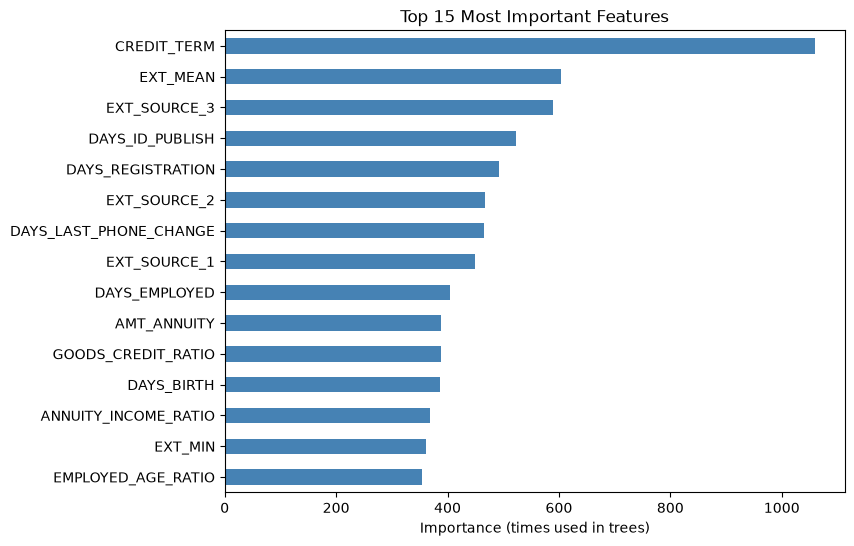

In [42]:
importance = pd.Series(lgbm_fe.feature_importances_, index=X_train_fe.columns)
top15 = importance.sort_values(ascending=False).head(15)

top15.sort_values().plot(kind="barh", figsize=(8, 6), color="steelblue")
plt.title("Top 15 Most Important Features")
plt.xlabel("Importance (times used in trees)")
plt.show()

In [43]:
from sklearn.metrics import confusion_matrix

for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (prob_fe >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"Threshold {t}: caught {tp}, missed {fn}, false alarms {fp}")

Threshold 0.3: caught 3402, missed 548, false alarms 24402
Threshold 0.4: caught 3005, missed 945, false alarms 17398
Threshold 0.5: caught 2545, missed 1405, false alarms 11737
Threshold 0.6: caught 1980, missed 1970, false alarms 7112
Threshold 0.7: caught 1296, missed 2654, false alarms 3515


In [44]:
import numpy as np

COST_MISSED = 500000    # loan lost when a defaulter is approved
COST_FALSE_ALARM = 50000  # interest lost when a good person is rejected

results = []
for t in np.arange(0.05, 0.96, 0.05):
    pred = (prob_fe >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    cost = fn * COST_MISSED + fp * COST_FALSE_ALARM
    results.append({"threshold": round(t, 2), "caught": tp, "missed": fn,
                    "false_alarms": fp, "cost_crore": round(cost / 1e7, 2)})

res = pd.DataFrame(results)
print(res)
best = res.loc[res["cost_crore"].idxmin()]
print("\nBest threshold:", best["threshold"], "| Cost: ₹", best["cost_crore"], "crore")

    threshold  caught  missed  false_alarms  cost_crore
0        0.05    3943       7         44346      222.08
1        0.10    3908      42         41246      208.33
2        0.15    3812     138         37045      192.12
3        0.20    3702     248         32625      175.52
4        0.25    3560     390         28386      161.43
5        0.30    3402     548         24402      149.41
6        0.35    3220     730         20705      140.02
7        0.40    3005     945         17398      134.24
8        0.45    2794    1156         14426      129.93
9        0.50    2545    1405         11737      128.94
10       0.55    2265    1685          9254      130.52
11       0.60    1980    1970          7112      134.06
12       0.65    1639    2311          5199      141.54
13       0.70    1296    2654          3515      150.28
14       0.75     972    2978          2100      159.40
15       0.80     586    3364           973      173.06
16       0.85     269    3681           298     

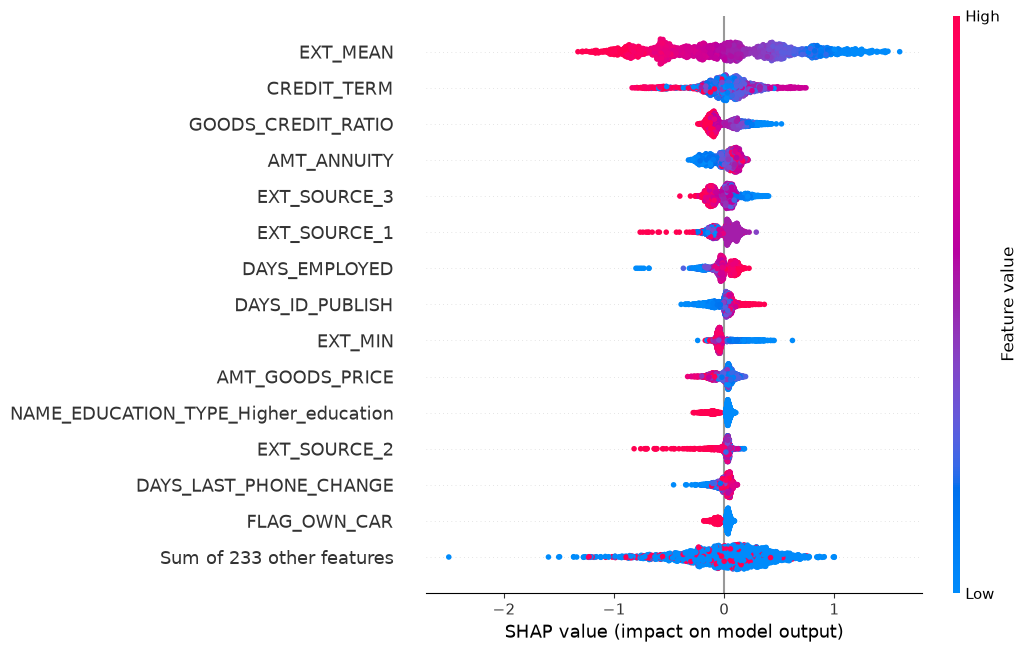

In [45]:
import shap

sample = X_test_fe.sample(2000, random_state=42)

explainer = shap.TreeExplainer(lgbm_fe)
shap_values = explainer(sample)

shap.plots.beeswarm(shap_values, max_display=15)


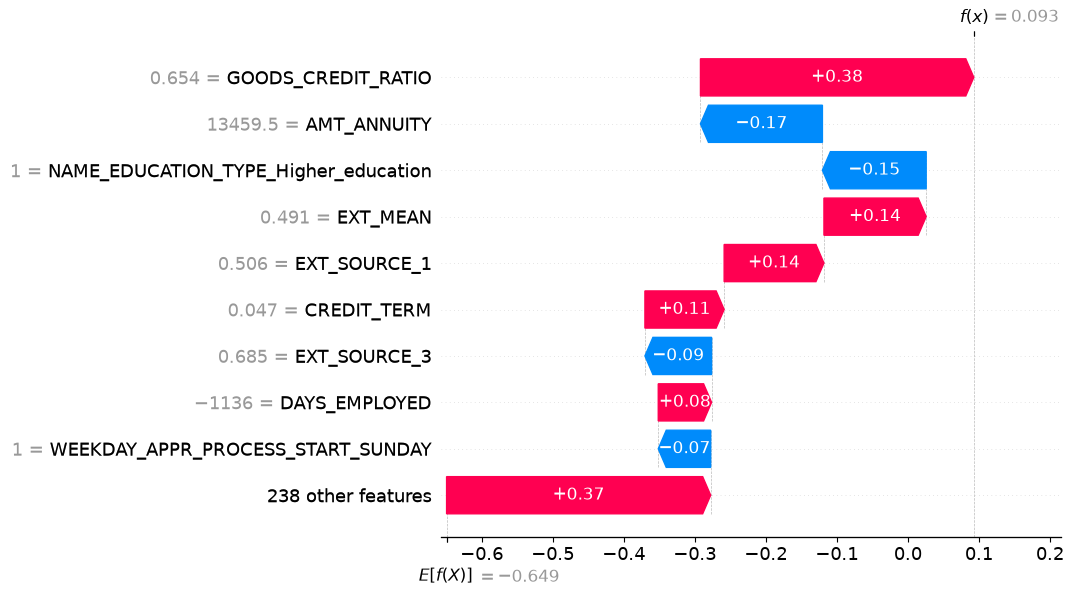

Predicted risk: 52.3 %


In [46]:
i = 0  # the first person in our sample
shap.plots.waterfall(shap_values[i], max_display=10)
print("Predicted risk:", round(lgbm_fe.predict_proba(sample.iloc[[i]])[0, 1] * 100, 1), "%")

In [47]:
person = shap_values[i]
reasons = pd.DataFrame({
    "feature": sample.columns,
    "value": sample.iloc[i].values,
    "impact": person.values
}).sort_values("impact", key=abs, ascending=False).head(5)

print(reasons)

                                  feature         value    impact
242                    GOODS_CREDIT_RATIO      0.654450  0.384798
6                             AMT_ANNUITY  13459.500000 -0.171685
127  NAME_EDUCATION_TYPE_Higher_education      1.000000 -0.146081
245                              EXT_MEAN      0.490991  0.143928
30                           EXT_SOURCE_1      0.506427  0.140498


In [48]:
FORM_COLS = [
    "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
    "DAYS_BIRTH", "DAYS_EMPLOYED", "DAYS_ID_PUBLISH", "DAYS_REGISTRATION",
    "DAYS_LAST_PHONE_CHANGE", "CNT_FAM_MEMBERS",
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
    "FLAG_OWN_CAR", "NAME_EDUCATION_TYPE_Higher_education"
]

Xf_train = add_features(X_train[FORM_COLS])
Xf_test = add_features(X_test[FORM_COLS])

form_model = lgb.LGBMClassifier(
    n_estimators=500, learning_rate=0.05, num_leaves=31,
    class_weight="balanced", random_state=42, verbose=-1
)
form_model.fit(Xf_train, y_train)

prob_form = form_model.predict_proba(Xf_test)[:, 1]
print("Form model ROC-AUC:", round(roc_auc_score(y_test, prob_form), 4))
print("Number of features:", Xf_train.shape[1])

Form model ROC-AUC: 0.7575
Number of features: 22


In [51]:
import joblib

joblib.dump({
    "model": form_model,
    "form_cols": FORM_COLS,
    "medians": train_medians[FORM_COLS],
    "threshold": 0.5
}, "../models/loan_model.joblib")

print("Saved! ✅")

Saved! ✅


In [50]:
def clean(c):
    return re.sub(r"[^A-Za-z0-9_]", "_", c)

X_train.columns = [clean(c) for c in X_train.columns]
X_test.columns = [clean(c) for c in X_test.columns]
train_medians.index = [clean(c) for c in train_medians.index]

print([c for c in X_train.columns if "EDUCATION" in c])

['NAME_EDUCATION_TYPE_Academic_degree', 'NAME_EDUCATION_TYPE_Higher_education', 'NAME_EDUCATION_TYPE_Incomplete_higher', 'NAME_EDUCATION_TYPE_Lower_secondary', 'NAME_EDUCATION_TYPE_Secondary___secondary_special']


In [52]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_fe, y_train, test_size=0.15, random_state=42, stratify=y_train
)

better = lgb.LGBMClassifier(
    n_estimators=5000,
    learning_rate=0.02,
    num_leaves=34,
    max_depth=8,
    min_child_samples=80,
    subsample=0.85,
    subsample_freq=1,
    colsample_bytree=0.5,
    reg_alpha=0.05,
    reg_lambda=0.1,
    random_state=42,
    verbose=-1
)
better.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(200), lgb.log_evaluation(200)]
)

prob_better = better.predict_proba(X_test_fe)[:, 1]
print("Best number of trees:", better.best_iteration_)
print("Improved ROC-AUC:", round(roc_auc_score(y_test, prob_better), 4))

C:\Users\dasra\loan-default-risk\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 200 rounds
[200]	valid_0's auc: 0.754876	valid_0's binary_logloss: 0.246293
[400]	valid_0's auc: 0.762174	valid_0's binary_logloss: 0.244066
[600]	valid_0's auc: 0.764228	valid_0's binary_logloss: 0.243456
[800]	valid_0's auc: 0.764765	valid_0's binary_logloss: 0.243275
[1000]	valid_0's auc: 0.765068	valid_0's binary_logloss: 0.243165
[1200]	valid_0's auc: 0.765191	valid_0's binary_logloss: 0.243126
Early stopping, best iteration is:
[1096]	valid_0's auc: 0.765226	valid_0's binary_logloss: 0.243089
Best number of trees: 1096
Improved ROC-AUC: 0.7641


In [53]:
def best_threshold(probs, y):
    rows = []
    for t in np.arange(0.02, 0.61, 0.01):
        pred = (probs >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
        cost = fn * COST_MISSED + fp * COST_FALSE_ALARM
        rows.append({"threshold": round(t, 2), "caught": tp, "missed": fn,
                     "false_alarms": fp, "cost_crore": round(cost / 1e7, 2)})
    r = pd.DataFrame(rows)
    return r.loc[r["cost_crore"].idxmin()]

print(best_threshold(prob_better, y_test))

threshold          0.10
caught          2404.00
missed          1546.00
false_alarms    9942.00
cost_crore       127.01
Name: 8, dtype: float64


In [54]:
Xf_tr, Xf_val, yf_tr, yf_val = train_test_split(
    Xf_train, y_train, test_size=0.15, random_state=42, stratify=y_train
)

form_better = lgb.LGBMClassifier(
    n_estimators=5000, learning_rate=0.02, num_leaves=34, max_depth=8,
    min_child_samples=80, subsample=0.85, subsample_freq=1,
    colsample_bytree=0.5, reg_alpha=0.05, reg_lambda=0.1,
    random_state=42, verbose=-1
)
form_better.fit(Xf_tr, yf_tr, eval_set=[(Xf_val, yf_val)], eval_metric="auc",
                callbacks=[lgb.early_stopping(200), lgb.log_evaluation(0)])

prob_form_better = form_better.predict_proba(Xf_test)[:, 1]
print("Form model ROC-AUC:", round(roc_auc_score(y_test, prob_form_better), 4))
print(best_threshold(prob_form_better, y_test))

C:\Users\dasra\loan-default-risk\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 200 rounds
Early stopping, best iteration is:
[746]	valid_0's auc: 0.760465	valid_0's binary_logloss: 0.244356
Form model ROC-AUC: 0.7617
threshold           0.09
caught           2573.00
missed           1377.00
false_alarms    11807.00
cost_crore        127.88
Name: 7, dtype: float64
